In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import warnings
warnings.filterwarnings('ignore')

%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid')


import os
import sys

notebook_dir = os.getcwd()
module_dir = os.path.abspath(os.path.join(notebook_dir, 'hnsw'))
if module_dir not in sys.path:
    sys.path.append(module_dir)
    
from hnsw import HNSW
from plot_hnsw import plot_hnsw_3d 

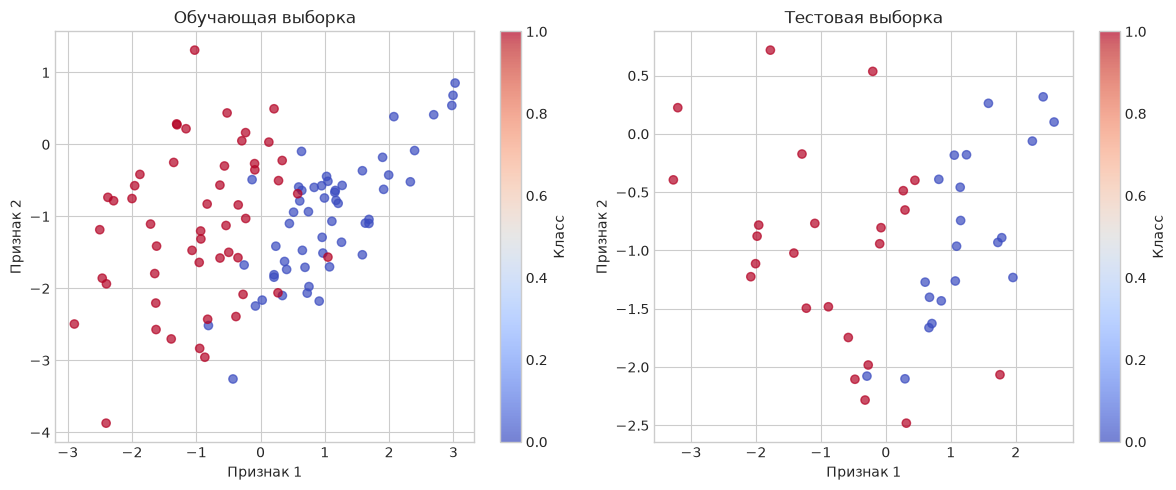

In [8]:
X, y = make_classification(
    n_samples=150,
    n_features=2,
    n_informative=2,
    n_redundant=0,
    n_clusters_per_class=1,
    random_state=46,
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap='coolwarm', alpha=0.7)
plt.title('Обучающая выборка')
plt.xlabel('Признак 1')
plt.ylabel('Признак 2')
plt.colorbar(label='Класс')

plt.subplot(1, 2, 2)
plt.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap='coolwarm', alpha=0.7)
plt.title('Тестовая выборка')
plt.xlabel('Признак 1')
plt.ylabel('Признак 2')
plt.colorbar(label='Класс')

plt.tight_layout()
plt.show()

Точность kNN с поиском k ближайших с помощью HNSW: 0.8933


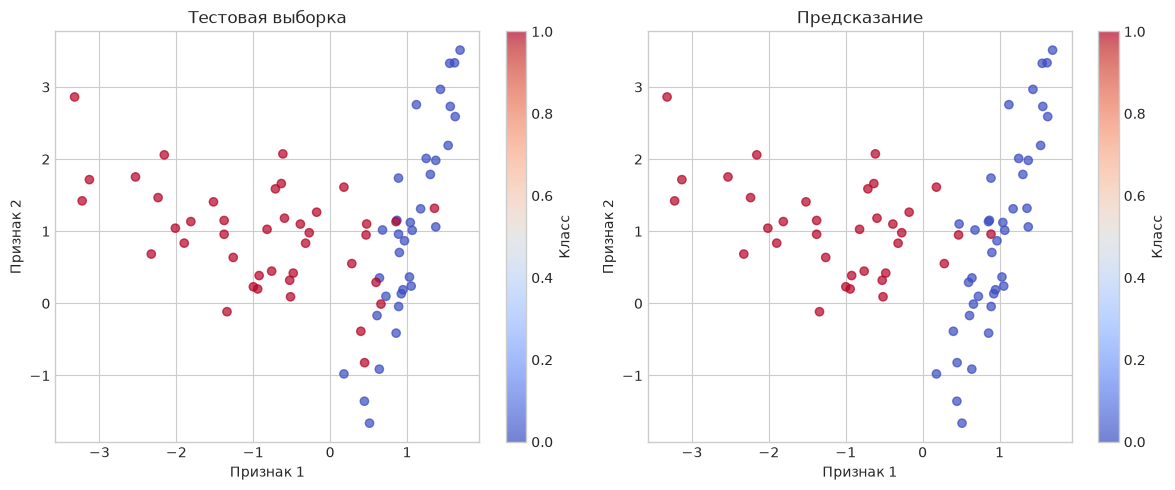

In [3]:
class KNNClassifier:
    def __init__(self, k=5, p=2):
        self.k = k
        self.p = p
        self.X_train = np.empty(())
        self.y_train = np.empty(())
        self.hnsw = HNSW()

    def _compute_distance(self, x1:np.ndarray, x2:np.ndarray):
        return np.sqrt(((x1-x2)**2).sum())

    def fit(self, X, y):
        self.X_train = X
        self.y_train = y
        for x in X:
            self.hnsw.add(x)
        return self

    def predict(self, X):
        predictions = []
        for x in X:
            k_nearest_indices = [idx for _, idx in self.hnsw.search(x, k = self.k)]
            k_nearest_labels = self.y_train[k_nearest_indices]

            unique_labels, counts = np.unique(k_nearest_labels, return_counts=True)
            predicted_label = unique_labels[np.argmax(counts)]
            predictions.append(predicted_label)

        return np.array(predictions)

knn_custom = KNNClassifier(k=5)
knn_custom.fit(X_train, y_train)
y_pred_custom = knn_custom.predict(X_test)

accuracy_custom = accuracy_score(y_test, y_pred_custom)
print(f"Точность kNN с поиском k ближайших с помощью HNSW: {accuracy_custom:.4f}")


plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 2)
plt.scatter(X_test[:, 0], X_test[:, 1], c=y_pred_custom, cmap='coolwarm', alpha=0.7)
plt.title('Предсказание')
plt.xlabel('Признак 1')
plt.ylabel('Признак 2')
plt.colorbar(label='Класс')

plt.subplot(1, 2, 1)
plt.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap='coolwarm', alpha=0.7)
plt.title('Тестовая выборка')
plt.xlabel('Признак 1')
plt.ylabel('Признак 2')
plt.colorbar(label='Класс')

plt.tight_layout()
plt.show()

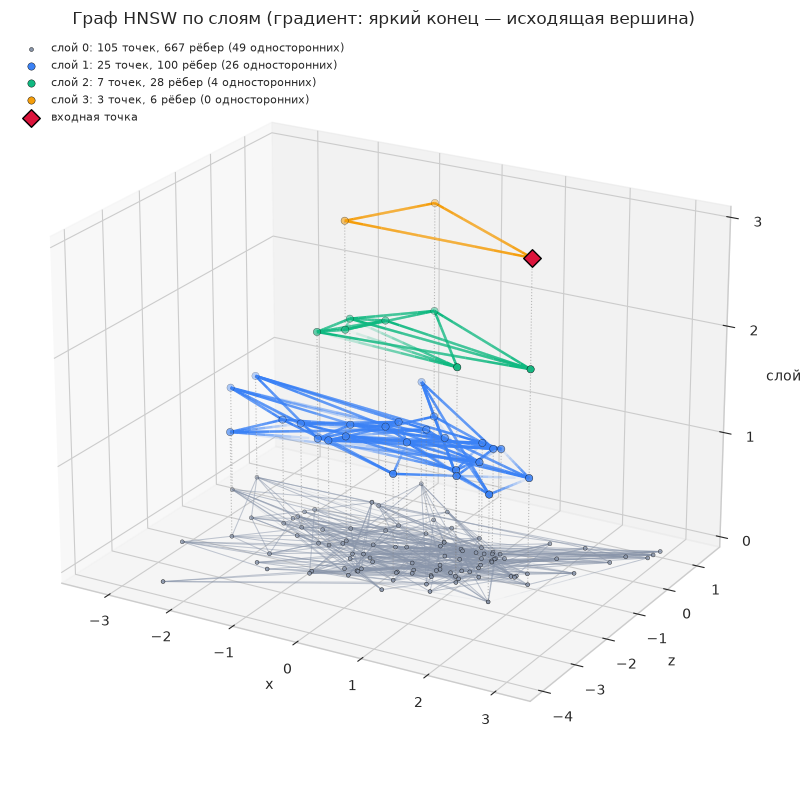

In [9]:
np.random.seed(35)

h = HNSW(M=4, efC=40)
for x in X_train:
    h.add(x)
     
plot_hnsw_3d(h, X)
plt.tight_layout()
plt.show()